# Capa Silver: datos limpios y comparables
## ¿Cuándo un accidente se convierte en colapso del tráfico? Accidentes de alto impacto en EE.UU. (2016–2023)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2

**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque

**Integrantes:**
    - Charca Condori Yordi Brayan
    - Chura Puma Cristian Erik
    - Condori Quispe Kewin Erick
    - Inofuente Trujillo David Alex
    - Vargas Idme Vladimir Yordanov

Este es el **segundo de tres notebooks** del proyecto. Sigue la arquitectura *medallion*: cada capa lee la anterior **sin modificarla** y deja evidencia de lo que hizo.

| # | Notebook | Capa | Qué hace |
|---|---|---|---|
| 1 | `01_exploration/02_eda_accidentes_eeuu.ipynb` | Bronze | Avance: comprensión del dataset y diagnóstico de calidad (no limpia nada) |
| 2 | `02_cleaning/03_silver_accidentes_eeuu.ipynb` (**este**) | Bronze → Silver | Elige columnas, aplica reglas de calidad, crea variables y guarda una tabla limpia |
| 3 | `03_analysis/04_analisis_accidentes_eeuu.ipynb` | Silver → Gold | Análisis en 4 niveles, tablas Gold y conclusiones |

> **Para reproducir:** abrir con el kernel del entorno del proyecto y ejecutar **Kernel → Restart & Run All** (1 a 3 minutos). Luego ejecutar el notebook 3.
> Este notebook necesita que el CSV original ya esté en Bronze; si no está, primero se ejecuta la celda 0.3 del notebook 1, que lo descarga de Kaggle.

---
## 0. Preparación reproducible

In [25]:
# Celda 0.1: localizar la raíz del proyecto y definir las capas de datos
import importlib.util
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Localiza la raíz del repositorio por sus carpetas data/ y notebooks/
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA (carpetas data/ y notebooks/).")


PROJECT_ROOT = find_project_root(Path.cwd())
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "us_accidents"
SILVER_DIR = PROJECT_ROOT / "data" / "silver" / "us_accidents"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "us_accidents"

for folder in (SILVER_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]}")
print(f"Bronze   : {BRONZE_DIR.relative_to(PROJECT_ROOT)}  (solo lectura)")
print(f"Silver   : {SILVER_DIR.relative_to(PROJECT_ROOT)}")

Proyecto : C:\Users\Erik\Documents\EDA-TF\EDA-bigdata
Python   : 3.12.10
Bronze   : data\bronze\us_accidents  (solo lectura)
Silver   : data\silver\us_accidents


In [2]:
# Celda 0.2: verificar dependencias sin modificar el entorno
REQUERIDAS = ["pandas", "numpy", "matplotlib"]
faltantes = [lib for lib in REQUERIDAS if importlib.util.find_spec(lib) is None]
if faltantes:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(faltantes) +
        ". Ejecute desde la raíz del proyecto: python -m pip install -r requirements.txt"
    )

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.titlesize": 12,
})


def guardar_figura(fig, nombre: str) -> None:
    # Guarda cada gráfico en outputs/us_accidents/ para el informe
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")


print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)

pandas    : 3.1.0
numpy     : 2.5.4


In [3]:
# Celda 0.3: comprobar que Bronze está completo (Silver nunca descarga ni modifica Bronze)
RUTA_BRONZE = BRONZE_DIR / "US_Accidents_March23.csv"
RUTA_MANIFEST = BRONZE_DIR / "manifest.json"

if not RUTA_BRONZE.is_file() or not RUTA_MANIFEST.is_file():
    raise FileNotFoundError(
        "Falta el CSV o el manifest en Bronze. Ejecute primero la celda 0.3 del notebook "
        "notebooks/01_exploration/02_eda_accidentes_eeuu.ipynb"
    )

manifest = json.loads(RUTA_MANIFEST.read_text(encoding="utf-8"))
archivo_bronze = manifest["files"][0]
if RUTA_BRONZE.stat().st_size != archivo_bronze["bytes"]:
    raise ValueError("El CSV de Bronze no tiene el tamaño registrado en el manifest: vuelva a descargarlo.")

print(f"Bronze verificado: {archivo_bronze['name']} · {archivo_bronze['bytes'] / 1024**3:.2f} GB · "
      f"SHA-256 {archivo_bronze['sha256'][:12]}…")

Bronze verificado: US_Accidents_March23.csv · 2.85 GB · SHA-256 e3e9f962e3e2…


---
## 1. Punto de partida: qué dejó pendiente el avance

El diagnóstico del avance (sección 9) encontró tres problemas. Esta capa los atiende así:

| # | Problema del avance | Tratamiento en Silver |
|---|---|---|
| 1 | **La severidad no se mide igual en todas las fuentes** (8 % de alto impacto en Source1 frente a 34 % en Source2) | Se conserva `Source` y se crea `grupo_severidad`: solo se comparan registros que usan el mismo criterio (sección 6) |
| 2 | **Precipitación incompleta** (28,58 % de nulos) | Se excluye la columna. El clima se describe con `Weather_Condition` agrupada y con `Visibility(mi)` |
| 3 | **Valores inválidos y posibles duplicados** | Los duplicados probables se **excluyen** y se guardan aparte; las duraciones irreales y el clima desfasado se **marcan** |

**Regla general de esta capa:** no se elimina ningún registro sin una regla escrita, un conteo y un archivo de respaldo.

---
## 2. Carga desde Bronze (la misma muestra del avance)

Se repite exactamente el procedimiento del avance: lectura por bloques de 500 000 filas, muestra aleatoria del 7 % de cada bloque y semilla fija 42. Así **los conteos de este notebook coinciden con los del avance**. Se leen las mismas 29 columnas para poder justificar con datos cuáles se quedan (sección 3).

In [7]:
# Celda 2.1: carga reproducible por bloques (misma muestra que el avance)
COLUMNAS_AVANCE = ["ID", "Source", "Severity", "Start_Time", "End_Time",
                   "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)",
                   "City", "State", "Zipcode", "Country", "Timezone",
                   "Weather_Timestamp", "Temperature(F)", "Humidity(%)", "Pressure(in)",
                   "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Weather_Condition",
                   "Traffic_Signal", "Crossing", "Junction", "Stop", "Roundabout", "Sunrise_Sunset"]
FRACCION, SEMILLA = 0.07, 42
TAMANO_BLOQUE = 500_000

t0 = time.perf_counter()
partes, filas_bronze = [], 0
for bloque in pd.read_csv(RUTA_BRONZE, usecols=COLUMNAS_AVANCE, dtype={"Zipcode": str}, chunksize=TAMANO_BLOQUE):
    filas_bronze += len(bloque)
    partes.append(bloque.sample(frac=FRACCION, random_state=SEMILLA))
muestra = pd.concat(partes, ignore_index=True)

print(f"Carga completada en {time.perf_counter() - t0:.0f} s")
print(f"Filas en Bronze        : {filas_bronze:,}")
print(f"Filas de la muestra 7 %: {len(muestra):,}  (el avance tenía 540,988)")

Carga completada en 35 s
Filas en Bronze        : 7,728,394
Filas de la muestra 7 %: 540,988  (el avance tenía 540,988)


---
## 3. Selección de columnas: regla del 3 % de nulos

**Regla:** una columna se usa en el análisis solo si tiene **como máximo 3 % de valores nulos** y si ayuda a responder una sub-pregunta.

**¿Por qué 3 %?** Si a una columna le falta el 3 % de los datos, aunque **todos** esos registros fueran de alto impacto, el porcentaje de alto impacto calculado sin ellos se movería como máximo unos 3 puntos. Con 28 % de faltantes (precipitación) el error posible llegaría a 28 puntos, y ninguna conclusión sería confiable.

Además se quitan columnas que, aunque estén completas, no aportan a la pregunta: así la tabla es más liviana y más fácil de explicar.

In [10]:
# Celda 3.1: decidir qué columnas pasan a Silver
MAX_NULOS = 3.0   # % máximo de nulos permitido en una columna del análisis

motivos_uso = {
    "ID": "Clave única del accidente",
    "Source": "Variable de control: cada fuente mide distinto la severidad",
    "Severity": "Variable objetivo (alto impacto = 3 o 4)",
    "Start_Time": "Sub-pregunta 1: cuándo (hora, día, año)",
    "End_Time": "Regla de consistencia (duración)",
    "Start_Lat": "Sub-pregunta 2: dónde (validez de la ubicación)",
    "Start_Lng": "Sub-pregunta 2: dónde (validez de la ubicación)",
    "City": "Sub-pregunta 2: dónde",
    "State": "Sub-pregunta 2: dónde",
    "Weather_Timestamp": "Regla de exactitud (¿el clima es del momento del accidente?)",
    "Visibility(mi)": "Sub-pregunta 3: clima",
    "Weather_Condition": "Sub-pregunta 3: clima",
    "Sunrise_Sunset": "Sub-pregunta 1: condición de luz (día/noche)",
    "Traffic_Signal": "Sub-pregunta 4: vía",
    "Crossing": "Sub-pregunta 4: vía",
    "Junction": "Sub-pregunta 4: vía",
    "Stop": "Sub-pregunta 4: vía",
}
motivos_exclusion = {
    "End_Lat": "Supera 3 % de nulos: solo Source1 registra el fin del tramo",
    "End_Lng": "Supera 3 % de nulos: solo Source1 registra el fin del tramo",
    "Precipitation(in)": "Supera 3 % de nulos",
    "Wind_Speed(mph)": "Supera 3 % de nulos",
    "Distance(mi)": "Sin nulos, pero 42,7 % de ceros no plausibles (avance 8.5)",
    "Temperature(F)": "No responde a las sub-preguntas (el clima se describe con Weather_Condition)",
    "Humidity(%)": "No responde a las sub-preguntas",
    "Pressure(in)": "No responde a las sub-preguntas",
    "Zipcode": "Detalle innecesario: City y State bastan",
    "Country": "Valor constante (US): no aporta información",
    "Timezone": "No se necesita: Start_Time ya está en hora local",
    "Roundabout": "Sin muestra: muy pocos accidentes en rotondas",
}

seleccion = pd.DataFrame({"% nulos": muestra.isna().mean().mul(100).round(2)})
seleccion["Decisión"] = np.where(seleccion.index.isin(list(motivos_exclusion)), "Se excluye", "Se usa")
seleccion["Motivo"] = [motivos_exclusion.get(c, motivos_uso.get(c)) for c in seleccion.index]
seleccion = seleccion.sort_values(["Decisión", "% nulos"], ascending=[False, False])

with pd.option_context("display.max_colwidth", None):
    display(seleccion)

COLUMNAS_SILVER = list(motivos_uso)
max_nulos_usadas = seleccion.loc[COLUMNAS_SILVER, "% nulos"].max()
assert max_nulos_usadas <= MAX_NULOS, "Una columna seleccionada supera el 3 % de nulos"
print(f"Columnas que pasan a Silver: {len(COLUMNAS_SILVER)} de {len(COLUMNAS_AVANCE)}")
print(f"Máximo de nulos entre las columnas usadas: {max_nulos_usadas:.2f} % (límite {MAX_NULOS} %)")
print(f"Accidentes en rotonda en la muestra: {muestra['Roundabout'].sum()}")

,% nulos,Decisión,Motivo
Visibility(mi),2.30,Se usa,Sub-pregunta 3: clima
Weather_Condition,2.26,Se usa,Sub-pregunta 3: clima
Weather_Timestamp,1.56,Se usa,Regla de exactitud (¿el clima es del momento del accidente?)
Sunrise_Sunset,0.31,Se usa,Sub-pregunta 1: condición de luz (día/noche)
ID,0.00,Se usa,Clave única del accidente
Source,0.00,Se usa,Variable de control: cada fuente mide distinto la severidad
Severity,0.00,Se usa,Variable objetivo (alto impacto = 3 o 4)
Start_Time,0.00,Se usa,"Sub-pregunta 1: cuándo (hora, día, año)"
End_Time,0.00,Se usa,Regla de consistencia (duración)
Start_Lat,0.00,Se usa,Sub-pregunta 2: dónde (validez de la ubicación)


Columnas que pasan a Silver: 17 de 29
Máximo de nulos entre las columnas usadas: 2.30 % (límite 3.0 %)
Accidentes en rotonda en la muestra: 17


In [11]:
# Celda 3.2: quedarse solo con las columnas seleccionadas
df = muestra[COLUMNAS_SILVER].copy()
del muestra          # libera memoria: Bronze sigue intacto en disco
df.shape

(540988, 17)

**Interpretación de la selección**

- Pasan **17 de 29 columnas**. La que más nulos tiene es `Visibility(mi)` con **2,30 %**, por debajo del límite de 3 %.
- Salen por **exceso de nulos**: `End_Lat`/`End_Lng` (44,02 %), `Precipitation(in)` (28,58 %) y `Wind_Speed(mph)` (7,39 %).
- Sale `Distance(mi)` aunque no tiene nulos: el avance mostró que el 42,7 % de sus valores son 0, un valor **posible pero no plausible** para un accidente que afecta el tráfico.
- Salen columnas completas pero que no responden la pregunta (`Temperature(F)`, `Humidity(%)`, `Pressure(in)`, `Zipcode`, `Country`, `Timezone`) y `Roundabout`, que tiene solo 17 casos en más de medio millón de accidentes.

---
## 4. Tipos de datos

Las fechas llegan como texto (avance, sección 5). Se convierten a fecha; si alguna no se puede leer queda como nula y se cuenta (no se inventa un valor).

In [12]:
# Celda 4.1: convertir fechas y revisar que no se pierdan valores en la conversión
for col in ["Start_Time", "End_Time", "Weather_Timestamp"]:
    nulos_antes = df[col].isna().sum()
    df[col] = pd.to_datetime(df[col], format="mixed", errors="coerce")
    print(f"{col:<18} fechas que no se pudieron leer: {df[col].isna().sum() - nulos_antes}")

df.info(memory_usage="deep")

Start_Time         fechas que no se pudieron leer: 0
End_Time           fechas que no se pudieron leer: 0
Weather_Timestamp  fechas que no se pudieron leer: 0
<class 'pandas.DataFrame'>
RangeIndex: 540988 entries, 0 to 540987
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   ID                 540988 non-null  str           
 1   Source             540988 non-null  str           
 2   Severity           540988 non-null  int64         
 3   Start_Time         540988 non-null  datetime64[ns]
 4   End_Time           540988 non-null  datetime64[ns]
 5   Start_Lat          540988 non-null  float64       
 6   Start_Lng          540988 non-null  float64       
 7   City               540969 non-null  str           
 8   State              540988 non-null  str           
 9   Weather_Timestamp  532555 non-null  datetime64[us]
 10  Visibility(mi)     528532 non-null  float64       
 11  Weather_

**Interpretación:** las tres fechas se convierten **sin perder ningún valor** (los 8 433 nulos de `Weather_Timestamp` ya venían vacíos desde Bronze). `Severity` es entera, las coordenadas y la visibilidad son decimales y los elementos de la vía son booleanos. La tabla ocupa mucho menos memoria que la carga del avance porque tiene 12 columnas menos.

---
## 5. Reglas de calidad en las 6 dimensiones

Se usan las seis dimensiones de **DAMA-DMBOK** vistas en clase. Cada regla dice **qué se exige**, **a cuántos registros afecta** y **qué se hace** con los que no cumplen:

| Dimensión | Pregunta que responde |
|---|---|
| **Completitud** | ¿Están los datos que necesitamos? |
| **Unicidad** | ¿Cada accidente aparece una sola vez? |
| **Validez** | ¿Los valores están dentro de su dominio posible? |
| **Consistencia** | ¿Los campos relacionados (y las fuentes) cuentan la misma historia? |
| **Exactitud (plausibilidad)** | ¿El dato describe bien la realidad del accidente? Sin una fuente externa para contrastar, se revisa si es creíble |
| **Oportunidad** | ¿El periodo cubierto es suficiente y vigente para la pregunta? |

**Tres tratamientos posibles:** *Excluir* (solo si el error contamina los conteos), *Marcar* (se crea una columna indicadora y se decide en el análisis) o *Conservar* (el problema no afecta o se maneja excluyendo el registro solo del análisis que usa esa columna).

In [13]:
# Celda 5.0: función para registrar cada regla
reglas = []


def evaluar(dimension, regla, cumple, tratamiento, base=None):
    # Registra una regla. base = registros a los que aplica (por defecto, todos)
    if base is None:
        base = pd.Series(True, index=df.index)
    cumple = cumple.fillna(False).astype(bool)
    evaluados = int(base.sum())
    incumplen = int((base & ~cumple).sum())
    reglas.append({
        "Dimensión": dimension, "Regla": regla, "Evaluados": evaluados, "Incumplen": incumplen,
        "% Cumple": round((evaluados - incumplen) / evaluados * 100, 2),
        "Tratamiento en Silver": tratamiento,
    })


con_dato = lambda c: df[c].notna()

In [14]:
# Celda 5.1: Completitud
for col in ["Severity", "Start_Time", "State"]:
    evaluar("Completitud", f"{col} no nulo", df[col].notna(), "Conservar (100 % completo)")
evaluar("Completitud", "City no nulo", df["City"].notna(),
        "Conservar; sin ciudad solo sale del análisis por ciudad")
evaluar("Completitud", "Weather_Condition no nulo", df["Weather_Condition"].notna(),
        "Conservar; sin clima solo sale del análisis de clima")
evaluar("Completitud", "Visibility(mi) no nulo", df["Visibility(mi)"].notna(),
        "Conservar; sin visibilidad solo sale del análisis de visibilidad")
evaluar("Completitud", "Sunrise_Sunset no nulo", df["Sunrise_Sunset"].notna(),
        "Conservar; sin dato solo sale del análisis día/noche")

In [15]:
# Celda 5.2: Unicidad
evaluar("Unicidad", "ID único", ~df["ID"].duplicated(keep=False), "Conservar (no hay repetidos)")
duplicado_probable = df.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"])   # deja el primero
evaluar("Unicidad", "Sin duplicado probable (mismo inicio y misma ubicación)", ~duplicado_probable,
        "EXCLUIR la copia (se conserva el primer registro)")

# Ejemplo: dos ID distintos con la misma hora y las mismas coordenadas
ejemplo = df[df.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"], keep=False)]
ejemplo.sort_values(["Start_Time", "ID"])[["ID", "Source", "Severity", "Start_Time", "Start_Lat", "Start_Lng", "City"]].head(4)

,ID,Source,Severity,Start_Time,Start_Lat,Start_Lng,City
28299,A-35167,Source2,2,2016-04-19 18:03:57,38.411682,-122.794876,Santa Rosa
11957,A-35198,Source2,2,2016-04-19 18:03:57,38.411682,-122.794876,Santa Rosa
232818,A-3422977,Source1,2,2016-05-26 14:13:10,33.829270,-117.460370,Corona
242899,A-3422980,Source1,2,2016-05-26 14:13:10,33.829270,-117.460370,Corona


In [16]:
# Celda 5.3: Validez
evaluar("Validez", "Severity entre 1 y 4", df["Severity"].between(1, 4), "Excluir si incumple")
evaluar("Validez", "Start_Time entre 2016 y marzo 2023",
        df["Start_Time"].between(pd.Timestamp("2016-01-01"), pd.Timestamp("2023-04-01")), "Excluir si incumple")
evaluar("Validez", "Coordenadas dentro de EE.UU. continental",
        df["Start_Lat"].between(24, 50) & df["Start_Lng"].between(-125, -66), "Excluir si incumple")
evaluar("Validez", "Visibility(mi) mayor o igual a 0", df["Visibility(mi)"] >= 0,
        "Convertir a nulo si incumple", base=con_dato("Visibility(mi)"))
evaluar("Validez", "Sunrise_Sunset es Day o Night", df["Sunrise_Sunset"].isin(["Day", "Night"]),
        "Convertir a nulo si incumple", base=con_dato("Sunrise_Sunset"))

In [17]:
# Celda 5.4: Consistencia entre columnas
duracion_min = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
evaluar("Consistencia", "End_Time posterior a Start_Time", duracion_min > 0, "Excluir si incumple")
evaluar("Consistencia", "Duración de máximo 24 h", duracion_min <= 24 * 60,
        "MARCAR (flag_duracion_irreal); la duración no se usa en el análisis")

In [18]:
# Celda 5.5: Exactitud (plausibilidad)
desfase_clima_s = (df["Weather_Timestamp"] - df["Start_Time"]).abs().dt.total_seconds()
evaluar("Exactitud (plausibilidad)", "Clima medido a máximo 1 h del accidente", desfase_clima_s <= 3600,
        "MARCAR (clima_confiable); el análisis de clima usa solo los confiables",
        base=con_dato("Weather_Timestamp"))

In [19]:
# Celda 5.6: Oportunidad
anio = df["Start_Time"].dt.year.rename("anio")
evaluar("Oportunidad", "Accidente en un año completo (2017–2022)", anio.between(2017, 2022),
        "MARCAR (anio_completo); no se comparan años incompletos")

In [20]:
# Celda 5.7: resultado consolidado de las reglas
calidad = pd.DataFrame(reglas)
with pd.option_context("display.max_colwidth", 80):
    display(calidad)

,Dimensión,Regla,Evaluados,Incumplen,% Cumple,Tratamiento en Silver
0,Completitud,Severity no nulo,540988,0,100.00,Conservar (100 % completo)
1,Completitud,Start_Time no nulo,540988,0,100.00,Conservar (100 % completo)
2,Completitud,State no nulo,540988,0,100.00,Conservar (100 % completo)
3,Completitud,City no nulo,540988,19,100.00,Conservar; sin ciudad solo sale del análisis por ciudad
4,Completitud,Weather_Condition no nulo,540988,12232,97.74,Conservar; sin clima solo sale del análisis de clima
5,Completitud,Visibility(mi) no nulo,540988,12456,97.70,Conservar; sin visibilidad solo sale del análisis de visibilidad
6,Completitud,Sunrise_Sunset no nulo,540988,1689,99.69,Conservar; sin dato solo sale del análisis día/noche
7,Unicidad,ID único,540988,0,100.00,Conservar (no hay repetidos)
8,Unicidad,Sin duplicado probable (mismo inicio y misma ubicación),540988,3698,99.32,EXCLUIR la copia (se conserva el primer registro)
9,Validez,Severity entre 1 y 4,540988,0,100.00,Excluir si incumple


**Interpretación de las reglas**

- **Completitud:** las variables centrales (`Severity`, `Start_Time`, `State`) están al 100 %. Las del clima tienen entre 97,7 % y 97,8 % de cumplimiento: los registros sin dato se mantienen en Silver y solo se apartan del análisis que necesita esa columna (como en el notebook de clase de Elecciones 2021, no se convierte una ausencia en un valor).
- **Unicidad:** el `ID` no se repite, pero **3 698 registros (0,68 %)** tienen exactamente el mismo inicio y las mismas coordenadas que otro. Es la **única regla que obliga a excluir**: un accidente contado dos veces infla los conteos por hora y lugar. El paper del dataset (Moosavi et al., 2019) ya eliminaba duplicados entre fuentes con un criterio parecido (menos de 250 m y 10 minutos).
- **Validez:** todas las reglas se cumplen al 100 %; no hay nada que corregir.
- **Consistencia:** ningún accidente termina antes de empezar, pero **2 474 (0,46 %)** duran más de 24 h. Se marcan y no se excluyen, porque la duración no se usa en el análisis.
- **Exactitud:** en **6 566 registros (1,23 % de los que tienen dato)** el clima se midió a más de 1 h del accidente. Según el paper, el clima se toma de la **estación de aeropuerto más cercana**; si además está desfasado, no describe bien el momento del accidente. Se marcan como no confiables para el análisis de clima.
- **Oportunidad:** 2016 (desde febrero) y 2023 (solo enero a marzo) son años incompletos; se marcan para no compararlos con años completos.

---
## 6. Consistencia en el tiempo: el hallazgo nuevo de esta capa

El avance mostró que la severidad cambia **entre fuentes**. Antes de comparar, falta revisar si también cambia **dentro de una misma fuente con el paso de los años**. Si una fuente cambió su criterio, mezclar sus años produciría tendencias falsas.

In [21]:
# Celda 6.1: % de alto impacto (severidad 3–4) por año y fuente
alto_impacto = df["Severity"] >= 3
conteo_fuente_anio = pd.crosstab(anio, df["Source"])
tasa_fuente_anio = pd.crosstab(anio, df["Source"], values=alto_impacto, aggfunc="mean").mul(100).round(1)

print("Accidentes por año y fuente")
display(conteo_fuente_anio)
print("% de alto impacto por año y fuente")
display(tasa_fuente_anio)

Accidentes por año y fuente


Source,Source1,Source2,Source3
anio,,,
2016,9119,19519,125
2017,11962,37790,534
2018,11684,50079,809
2019,18348,47064,1325
2020,49581,31397,1502
2021,77986,30201,1291
2022,106844,15377,1153
2023,17298,0,0


% de alto impacto por año y fuente


Source,Source1,Source2,Source3
anio,,,
2016,28.8,36.9,39.2
2017,32.7,36.6,49.8
2018,33.2,35.9,48.5
2019,20.8,30.4,36.8
2020,10.2,30.5,29.4
2021,2.5,34.2,17.7
2022,2.7,34.1,22.6
2023,2.9,NaN,NaN


NameError: name 'guardar_figura' is not defined

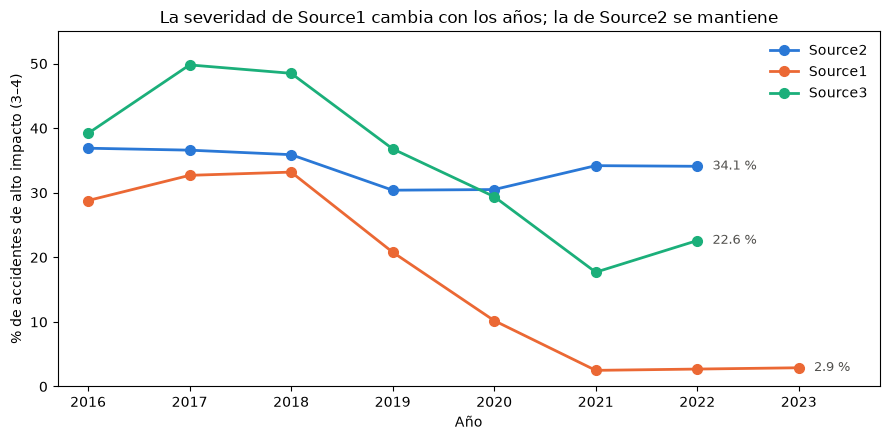

In [26]:
# Celda 6.2: gráfico de la tendencia por fuente
COLORES_FUENTE = {"Source2": "#2a78d6", "Source1": "#eb6834", "Source3": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 4.5))
for fuente, color in COLORES_FUENTE.items():
    serie = tasa_fuente_anio[fuente].dropna()
    ax.plot(serie.index, serie.values, marker="o", markersize=7, linewidth=2, color=color, label=fuente)
    ax.text(serie.index[-1] + 0.15, serie.values[-1], f"{serie.values[-1]:.1f} %", va="center", fontsize=9, color="#52514e")
ax.set_xlim(2015.7, 2023.8)
ax.set_ylim(0, 55)
ax.set_xlabel("Año")
ax.set_ylabel("% de accidentes de alto impacto (3–4)")
ax.set_title("La severidad de Source1 cambia con los años; la de Source2 se mantiene")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
guardar_figura(fig, "silver_01_alto_impacto_por_fuente_y_anio")
plt.show()

In [27]:
# Celda 6.3: ¿qué niveles de severidad usa Source1 cada año?
pd.crosstab(anio[df["Source"] == "Source1"], df.loc[df["Source"] == "Source1", "Severity"])

Severity,1,2,3,4
anio,,,,
2016,0,6496,1582,1041
2017,0,8050,2205,1707
2018,0,7804,2125,1755
2019,0,14526,2121,1701
2020,2013,42501,3222,1845
2021,0,76053,0,1933
2022,0,103967,0,2877
2023,0,16795,0,503


**Interpretación: la severidad tampoco es estable en el tiempo**

- **Source2** mantiene entre **30 % y 37 %** de accidentes de alto impacto todos los años (2016–2022): su criterio parece estable. (En 2022 empieza a usar el nivel 1 en vez del 2, pero la proporción de niveles 3–4 sigue en 34 %).
- **Source1** baja de **~33 %** (2016–2018) a **10 %** (2020) y a **menos de 3 %** desde 2021. Además, desde 2021 **ya no usa el nivel 3**: solo registra niveles 2 y 4.
- **Source3** es pequeña (1,25 % de la muestra) y también varía.

**¿Es creíble que los colapsos del tráfico se hayan reducido 10 veces en 4 años?** No parece plausible; es más probable que **Source1 haya cambiado su forma de asignar la severidad**. Esto es una **hipótesis**: solo el mantenedor del dataset puede confirmarla.

**Decisión: grupos comparables.** La severidad solo se comparará dentro de grupos que usan un criterio estable (registros contados después de excluir duplicados, sección 7):

| Grupo | Registros | Por qué es comparable |
|---|---|---|
| **A: Source2 2016–2022** | 231 374 | Proporción de alto impacto estable (30–37 %) en todos sus años (feb-2016 a sep-2022) |
| **B: Source1 2021–2023** | 199 249 | Proporción estable (2,5–2,9 %) y mismo uso de niveles (2 y 4) |
| **Sin comparar** | 106 667 | Source1 2016–2020 (criterio en transición) y Source3 (muy pocos registros) |

Los registros "sin comparar" **no se borran**: siguen sirviendo para contar accidentes por hora o lugar; solo no se usan para comparar severidad. Un patrón se considerará confiable si aparece **en los dos grupos**, que son fuentes y periodos distintos.

---
## 7. Tratamiento: excluir, marcar y crear variables

In [28]:
# Celda 7.1: excluir los duplicados probables (se guardan aparte para auditoría)
rechazados = df[duplicado_probable].copy()
rechazados["motivo_rechazo"] = "Duplicado probable: mismo Start_Time, Start_Lat y Start_Lng que otro registro"
silver = df[~duplicado_probable].copy()

print(f"Registros de la muestra : {len(df):,}")
print(f"Excluidos (duplicados)  : {len(rechazados):,} ({len(rechazados) / len(df):.2%})")
print(f"Registros en Silver     : {len(silver):,}")
print("\nExcluidos por fuente:")
print(rechazados["Source"].value_counts().to_string())

Registros de la muestra : 540,988
Excluidos (duplicados)  : 3,698 (0.68%)
Registros en Silver     : 537,290

Excluidos por fuente:
Source
Source1    3641
Source2      53
Source3       4


**Interpretación:** casi todos los duplicados (3 641 de 3 698) vienen de **Source1**: son el mismo accidente con dos `ID` distintos, misma hora y mismas coordenadas (ver el ejemplo de la celda 5.2). Excluirlos cambia muy poco el total (0,68 %) pero evita contar dos veces el mismo hecho.

In [29]:
# Celda 7.2: marcas de calidad (no eliminan registros)
silver["duracion_min"] = (silver["End_Time"] - silver["Start_Time"]).dt.total_seconds() / 60
silver["flag_duracion_irreal"] = silver["duracion_min"] > 24 * 60

desfase = (silver["Weather_Timestamp"] - silver["Start_Time"]).abs().dt.total_seconds()
silver["clima_confiable"] = desfase <= 3600      # sin hora del clima → False

silver["anio"] = silver["Start_Time"].dt.year
silver["anio_completo"] = silver["anio"].between(2017, 2022)

silver[["flag_duracion_irreal", "clima_confiable", "anio_completo"]].mean().mul(100).round(2).to_frame("% True")

,% True
flag_duracion_irreal,0.45
clima_confiable,97.23
anio_completo,91.46


In [30]:
# Celda 7.3: variables de tiempo
DIAS = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}


def franja_horaria(hora):
    # Franjas usadas por los autores del dataset (Moosavi et al., 2019, nota 7)
    if 6 <= hora < 10:
        return "06-10 Punta mañana"
    if 10 <= hora < 15:
        return "10-15 Mediodía"
    if 15 <= hora < 19:
        return "15-19 Punta tarde"
    if 19 <= hora < 22:
        return "19-22 Noche"
    return "22-06 Madrugada"


silver["mes"] = silver["Start_Time"].dt.month
silver["hora"] = silver["Start_Time"].dt.hour
silver["franja_horaria"] = silver["hora"].map(franja_horaria)
silver["dia_semana"] = silver["Start_Time"].dt.day_of_week.map(DIAS)
silver["tipo_dia"] = np.where(silver["Start_Time"].dt.day_of_week >= 5, "Fin de semana", "Laborable")

silver[["Start_Time", "anio", "mes", "hora", "franja_horaria", "dia_semana", "tipo_dia"]].head()

,Start_Time,anio,mes,hora,franja_horaria,dia_semana,tipo_dia
0,2016-04-25 17:18:11,2016,4,17,15-19 Punta tarde,Lunes,Laborable
1,2017-01-10 09:40:16,2017,1,9,06-10 Punta mañana,Martes,Laborable
2,2016-09-02 17:27:56,2016,9,17,15-19 Punta tarde,Viernes,Laborable
3,2016-09-29 18:07:37,2016,9,18,15-19 Punta tarde,Jueves,Laborable
4,2017-05-03 12:12:18,2017,5,12,10-15 Mediodía,Miércoles,Laborable


In [31]:
# Celda 7.4: agrupar las descripciones del clima en pocas categorías
def agrupar_clima(texto):
    # El orden importa: "Light Rain with Thunder" es tormenta, no lluvia
    t = texto.lower()
    if "thunder" in t or "t-storm" in t:
        return "Tormenta"
    if any(p in t for p in ["snow", "sleet", "wintry", "freezing", "ice", "hail"]):
        return "Nieve o hielo"
    if any(p in t for p in ["rain", "drizzle", "shower"]):
        return "Lluvia"
    if any(p in t for p in ["fog", "mist", "haze", "smoke", "dust", "sand"]):
        return "Niebla o humo"
    if "cloud" in t or "overcast" in t:
        return "Nublado"
    if "fair" in t or "clear" in t:
        return "Despejado"
    return "Otro"


mapa_clima = {texto: agrupar_clima(texto) for texto in silver["Weather_Condition"].dropna().unique()}
silver["clima_grupo"] = silver["Weather_Condition"].map(mapa_clima)

resumen_clima = (pd.Series(mapa_clima, name="grupo").rename_axis("descripcion").reset_index()
                 .groupby("grupo")["descripcion"]
                 .agg(descripciones_originales="size", ejemplos=lambda s: ", ".join(s.head(4))))
resumen_clima["accidentes"] = silver["clima_grupo"].value_counts()
with pd.option_context("display.max_colwidth", None):
    display(resumen_clima.sort_values("accidentes", ascending=False))

,descripciones_originales,ejemplos,accidentes
grupo,,,
Despejado,3,"Clear, Fair, Fair / Windy",236357
Nublado,8,"Partly Cloudy, Scattered Clouds, Overcast, Mostly Cloudy",220273
Lluvia,19,"Light Rain, Rain, Light Drizzle, Heavy Rain",35606
Niebla o humo,20,"Fog, Haze, Mist, Smoke",14123
Nieve o hielo,35,"Light Snow, Light Freezing Rain, Light Ice Pellets, Snow",12349
Tormenta,18,"Heavy Thunderstorms and Rain, Light Thunderstorms and Rain, Thunderstorms and Rain, Thunderstorm",6182
Otro,5,"Volcanic Ash, N/A Precipitation, Squalls / Windy, Squalls",250


In [32]:
# Celda 7.5: visibilidad en rangos, alto impacto y grupo comparable
silver["visibilidad_grupo"] = pd.cut(silver["Visibility(mi)"], bins=[0, 1, 5, np.inf], right=False,
                                     labels=["Muy reducida (<1 mi)", "Reducida (1-5 mi)", "Normal (>=5 mi)"])
silver["alto_impacto"] = silver["Severity"] >= 3

silver["grupo_severidad"] = "Sin comparar"
silver.loc[silver["Source"] == "Source2", "grupo_severidad"] = "A: Source2 2016-2022"
silver.loc[(silver["Source"] == "Source1") & (silver["anio"] >= 2021), "grupo_severidad"] = "B: Source1 2021-2023"

grupos = (silver.groupby("grupo_severidad")
          .agg(accidentes=("ID", "size"), alto_impacto=("alto_impacto", "sum"),
               desde=("Start_Time", "min"), hasta=("Start_Time", "max")))
grupos["% alto impacto"] = (grupos["alto_impacto"] / grupos["accidentes"] * 100).round(2)
grupos["% de Silver"] = (grupos["accidentes"] / len(silver) * 100).round(2)
display(grupos)
print(silver["visibilidad_grupo"].value_counts(dropna=False).to_string())

,accidentes,alto_impacto,desde,hasta,% alto impacto,% de Silver
grupo_severidad,,,,,,
A: Source2 2016-2022,231374,78438,2016-02-08 07:59:35,2022-09-08 14:40:33,33.90,43.06
B: Source1 2021-2023,199249,5158,2021-01-01 00:05:00,2023-03-31 22:59:30,2.59,37.08
Sin comparar,106667,21363,2016-02-08 21:10:10,2022-09-08 10:58:38,20.03,19.85


visibilidad_grupo
Normal (>=5 mi)         481550
Reducida (1-5 mi)        35189
NaN                      12367
Muy reducida (<1 mi)      8184


**Interpretación de las variables creadas**

- `franja_horaria` usa las **cinco franjas que los autores del dataset definieron** para su modelo (06–10, 10–15, 15–19, 19–22 y 22–06), así el análisis se apoya en un criterio externo y no en uno inventado.
- `clima_grupo` resume las más de 100 descripciones de `Weather_Condition` en 7 grupos. "Despejado" y "Nublado" reúnen la gran mayoría; "Otro" (tornado, ceniza volcánica, ráfagas) tiene muy pocos casos y no se interpretará.
- `visibilidad_grupo` separa la visibilidad reducida: como el sensor suele reportar un máximo de 10 millas (avance 6.2), la mayoría queda en "Normal".
- `grupo_severidad` aplica la decisión de la sección 6: **A** tiene 33,9 % de alto impacto y **B** 2,6 %. Los dos porcentajes **no se comparan entre sí**; cada patrón se compara contra el promedio de su propio grupo.

---
## 8. Diccionario de la tabla Silver

Se documentan las columnas que llegan desde Bronze y las que se crearon en esta capa. Las definiciones de los elementos de la vía y del clima se tomaron del **paper del dataset** (Moosavi et al., 2019, secciones 4.2.2 y 4.2.3).

In [33]:
# Celda 8.1: diccionario de datos de Silver
diccionario_silver = pd.DataFrame([
    ("ID", "Bronze", "Identificador único del accidente", "Identificador", "Texto único", "Unicidad"),
    ("Source", "Bronze", "Proveedor que reportó el accidente", "Categórica nominal", "Source1, Source2, Source3", "Variable de control"),
    ("grupo_severidad", "Derivada", "Grupo en el que la severidad es comparable", "Categórica nominal", "A: Source2 2016-2022 · B: Source1 2021-2023 · Sin comparar", "Toda comparación de severidad se hace dentro del grupo"),
    ("Severity", "Bronze", "Impacto del accidente en el tráfico (no en las personas)", "Categórica ordinal", "1 (bajo) a 4 (alto)", "Variable objetivo"),
    ("alto_impacto", "Derivada", "True si Severity es 3 o 4", "Booleana", "True / False", "Define el 'colapso del tráfico'"),
    ("Start_Time", "Bronze", "Inicio del accidente (hora local)", "Temporal", "Feb-2016 a mar-2023", "Cuándo"),
    ("End_Time", "Bronze", "Fin del impacto en el tráfico", "Temporal", "Posterior a Start_Time", "Regla de consistencia"),
    ("duracion_min", "Derivada", "Minutos entre inicio y fin", "Numérica continua", "Minutos, > 0", "Solo control de calidad (depende de la fuente)"),
    ("flag_duracion_irreal", "Derivada", "True si la duración supera 24 h", "Booleana", "True / False", "Marca de consistencia"),
    ("anio / mes / hora", "Derivada", "Partes de Start_Time", "Numérica discreta", "2016–2023 · 1–12 · 0–23", "Cuándo"),
    ("anio_completo", "Derivada", "True si el año tiene 12 meses de datos (2017–2022)", "Booleana", "True / False", "Marca de oportunidad"),
    ("franja_horaria", "Derivada", "Franja del día definida por los autores del dataset", "Categórica ordinal", "06-10, 10-15, 15-19, 19-22, 22-06", "Cuándo"),
    ("dia_semana / tipo_dia", "Derivada", "Día de la semana y si es laborable o fin de semana", "Categórica", "Lunes…Domingo · Laborable / Fin de semana", "Cuándo"),
    ("Sunrise_Sunset", "Bronze", "Día o noche según la posición del sol", "Categórica binaria", "Day / Night", "Condición de luz"),
    ("Start_Lat / Start_Lng", "Bronze", "Coordenadas del accidente", "Numérica continua", "Lat. 24–50 · long. −125 a −66", "Dónde"),
    ("City / State", "Bronze", "Ciudad y estado (obtenidos de las coordenadas)", "Categórica nominal", "49 estados", "Dónde"),
    ("Weather_Timestamp", "Bronze", "Hora de la observación del clima", "Temporal", "Cercana a Start_Time", "Regla de exactitud"),
    ("clima_confiable", "Derivada", "True si el clima se midió a máximo 1 h del accidente", "Booleana", "True / False", "Filtro del análisis de clima"),
    ("Weather_Condition", "Bronze", "Clima descrito en texto (estación de aeropuerto más cercana)", "Categórica nominal", "Fair, Rain, Snow, Fog…", "Origen de clima_grupo"),
    ("clima_grupo", "Derivada", "Clima agrupado", "Categórica nominal", "Despejado, Nublado, Lluvia, Tormenta, Nieve o hielo, Niebla o humo, Otro", "Clima"),
    ("Visibility(mi)", "Bronze", "Distancia a la que se ve con claridad", "Numérica continua", "Millas, ≥ 0 (tope habitual 10)", "Clima"),
    ("visibilidad_grupo", "Derivada", "Visibilidad en tres rangos", "Categórica ordinal", "<1 mi · 1–5 mi · ≥5 mi", "Clima"),
    ("Junction", "Bronze", "Rampa, salida o entrada de autopista a ≤ 100 m (OpenStreetMap)", "Booleana", "True / False", "Vía"),
    ("Traffic_Signal", "Bronze", "Semáforo a ≤ 30 m (OpenStreetMap)", "Booleana", "True / False", "Vía"),
    ("Crossing", "Bronze", "Cruce peatonal o ciclista a ≤ 30 m (OpenStreetMap)", "Booleana", "True / False", "Vía"),
    ("Stop", "Bronze", "Señal de pare a ≤ 30 m (OpenStreetMap)", "Booleana", "True / False", "Vía"),
], columns=["Columna", "Origen", "Descripción", "Tipo o escala", "Unidad o dominio", "Uso en el análisis"])

with pd.option_context("display.max_colwidth", None):
    display(diccionario_silver)

,Columna,Origen,Descripción,Tipo o escala,Unidad o dominio,Uso en el análisis
0,ID,Bronze,Identificador único del accidente,Identificador,Texto único,Unicidad
1,Source,Bronze,Proveedor que reportó el accidente,Categórica nominal,"Source1, Source2, Source3",Variable de control
2,grupo_severidad,Derivada,Grupo en el que la severidad es comparable,Categórica nominal,A: Source2 2016-2022 · B: Source1 2021-2023 · Sin comparar,Toda comparación de severidad se hace dentro del grupo
3,Severity,Bronze,Impacto del accidente en el tráfico (no en las personas),Categórica ordinal,1 (bajo) a 4 (alto),Variable objetivo
4,alto_impacto,Derivada,True si Severity es 3 o 4,Booleana,True / False,Define el 'colapso del tráfico'
5,Start_Time,Bronze,Inicio del accidente (hora local),Temporal,Feb-2016 a mar-2023,Cuándo
6,End_Time,Bronze,Fin del impacto en el tráfico,Temporal,Posterior a Start_Time,Regla de consistencia
7,duracion_min,Derivada,Minutos entre inicio y fin,Numérica continua,"Minutos, > 0",Solo control de calidad (depende de la fuente)
8,flag_duracion_irreal,Derivada,True si la duración supera 24 h,Booleana,True / False,Marca de consistencia
9,anio / mes / hora,Derivada,Partes de Start_Time,Numérica discreta,2016–2023 · 1–12 · 0–23,Cuándo


> **Corrección respecto del avance:** el glosario del avance describía `Junction` como "¿ocurrió en una intersección?". Según el paper del dataset (tabla 2), `Junction` significa **rampa, salida o entrada de autopista**; las intersecciones se reflejan en `Crossing`, `Stop` y `Traffic_Signal`. Además, estos elementos no se observan en el lugar: se asignan si el mapa de OpenStreetMap tiene uno a menos de 30 m (o 100 m para `Junction`) del accidente, así que son una **aproximación**.

---
## 9. Guardar Silver y registrar la trazabilidad

Se guardan cuatro archivos en `data/silver/us_accidents/`:

| Archivo | Contenido |
|---|---|
| `us_accidents_silver.csv` | La tabla limpia que usa el análisis |
| `rechazados_duplicados.csv` | Los registros excluidos y el motivo (auditoría) |
| `reglas_calidad_silver.csv` y `diccionario_silver.csv` | Metadatos de la capa |
| `registro_silver.json` | Linaje: de qué archivo se partió, cuántas filas entraron y salieron, y cuándo se generó |

In [34]:
# Celda 9.1: ordenar columnas y guardar la capa Silver
ORDEN_SILVER = ["ID", "Source", "grupo_severidad", "Severity", "alto_impacto",
                "Start_Time", "End_Time", "duracion_min", "flag_duracion_irreal",
                "anio", "anio_completo", "mes", "hora", "franja_horaria", "dia_semana", "tipo_dia", "Sunrise_Sunset",
                "Start_Lat", "Start_Lng", "City", "State",
                "Weather_Timestamp", "clima_confiable", "Weather_Condition", "clima_grupo",
                "Visibility(mi)", "visibilidad_grupo",
                "Junction", "Traffic_Signal", "Crossing", "Stop"]
silver = silver[ORDEN_SILVER]

FORMATO_FECHA = "%Y-%m-%d %H:%M:%S"
silver.to_csv(SILVER_DIR / "us_accidents_silver.csv", index=False, date_format=FORMATO_FECHA)
rechazados.to_csv(SILVER_DIR / "rechazados_duplicados.csv", index=False, date_format=FORMATO_FECHA)
calidad.to_csv(SILVER_DIR / "reglas_calidad_silver.csv", index=False, encoding="utf-8-sig")
diccionario_silver.to_csv(SILVER_DIR / "diccionario_silver.csv", index=False, encoding="utf-8-sig")

registro = {
    "capa": "silver",
    "origen": "data/bronze/us_accidents/" + archivo_bronze["name"],
    "sha256_origen": archivo_bronze["sha256"],
    "filas_bronze": filas_bronze,
    "muestra": {"fraccion": FRACCION, "semilla": SEMILLA, "filas": len(df)},
    "excluidas_duplicado_probable": len(rechazados),
    "filas_silver": len(silver),
    "columnas_silver": ORDEN_SILVER,
    "generado_utc": datetime.now(timezone.utc).isoformat(),
}
(SILVER_DIR / "registro_silver.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False), encoding="utf-8")

for archivo in sorted(SILVER_DIR.iterdir()):
    print(f"  {archivo.relative_to(PROJECT_ROOT)}  ({archivo.stat().st_size / 1024**2:.1f} MB)")

  data\silver\us_accidents\diccionario_silver.csv  (0.0 MB)
  data\silver\us_accidents\rechazados_duplicados.csv  (0.8 MB)
  data\silver\us_accidents\registro_silver.json  (0.0 MB)
  data\silver\us_accidents\reglas_calidad_silver.csv  (0.0 MB)
  data\silver\us_accidents\us_accidents_silver.csv  (145.2 MB)


---
## 10. Resumen de la capa Silver

**Linaje:** CSV original en Bronze (7 728 394 filas) → muestra fija del 7 % (540 988) → 17 columnas con ≤ 3 % de nulos → fechas convertidas → 18 reglas en 6 dimensiones → 3 698 duplicados probables excluidos → marcas de calidad y variables nuevas → **Silver: 537 290 accidentes y 31 columnas**.

| Qué se hizo | Por qué |
|---|---|
| Se redujeron las columnas de 29 a 17 | Regla del 3 % de nulos y relevancia para la pregunta |
| Se excluyeron 3 698 duplicados probables (0,68 %) | Inflaban los conteos; se guardaron aparte |
| Se marcaron duraciones irreales, clima desfasado y años incompletos | Se deciden en el análisis, sin perder registros |
| Se crearon franja horaria, clima agrupado y visibilidad en rangos | Variables fáciles de explicar y comparar |
| Se crearon dos **grupos comparables** de severidad | La severidad cambia entre fuentes **y** dentro de Source1 con los años |

**Siguiente paso:** el notebook `03_analysis/04_analisis_accidentes_eeuu.ipynb` lee esta tabla (en segundos, sin volver a leer los 3 GB de Bronze), construye la capa Gold y desarrolla el análisis.